### **D2 / Image Features**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from src.gmm import GMM
from src.knn import KNN
from src.lda import LDA
from src.pca import PCA
from src.svm import SVM
from src.plotting import plot_pca_2d


### **Load Data**

In [2]:
def load_split(split):
    X = np.loadtxt(f"./data/image_features/{split}_data.csv", delimiter=",")
    y = np.loadtxt(f"./data/image_features/{split}_label.csv", delimiter=",").astype(int)
    return X, y


X_train, y_train = load_split("train")
X_val, y_val = load_split("val")
X_test, y_test = load_split("test")


In [3]:
classes = np.unique(y_train)
print("Class order:", classes)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Class order: [0 1 2 3 4]
Train: (2000, 36)
Validation: (500, 36)
Test: (500, 36)


### **2D PCA Visualization**

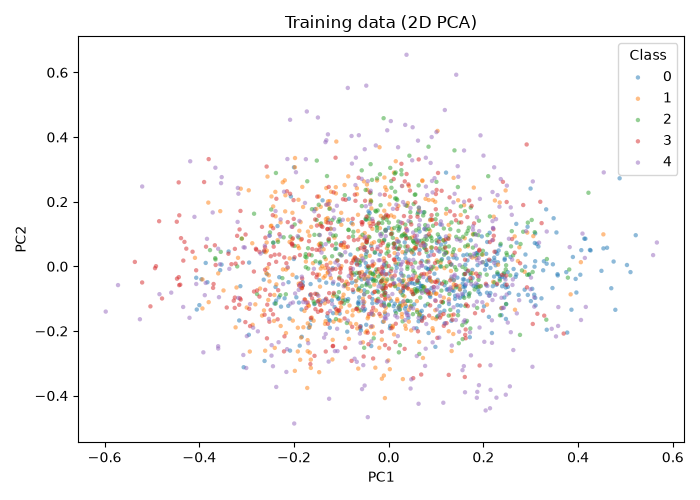

In [4]:
plot_pca_2d(X_train, y_train)


### **GMM**

In [5]:
models = []
priors = []
for label in classes:
    samples = X_train[y_train == label]
    model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    model.fit(samples)
    models.append(model)
    priors.append(len(samples) / len(X_train))
    print("Class", label, "EM iterations:", len(model.log_likelihoods))
    if len(model.log_likelihoods) == model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 0 EM iterations: 18
Class 1 EM iterations: 17
Class 2 EM iterations: 20
Class 3 EM iterations: 26
Class 4 EM iterations: 27


In [6]:
val_scores = np.column_stack([model.score_samples(X_val) for model in models])
gmm_val_predictions = classes[np.argmax(val_scores + np.log(priors), axis=1)]

test_scores = np.column_stack([model.score_samples(X_test) for model in models])
gmm_test_predictions = classes[np.argmax(test_scores + np.log(priors), axis=1)]


In [7]:
# Confusion matrix
gmm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_confusion)


Validation accuracy: 0.626
Test accuracy: 0.574
Test confusion matrix:
 [[62  7 16  9  6]
 [ 7 75  8  5  5]
 [ 6  3 68 15  8]
 [ 8  4 29 37 22]
 [ 4  3 18 30 45]]


### **KNN**

In [8]:
knn = KNN(k=5)
knn.fit(X_train, y_train)
knn_val_predictions = knn.predict(X_val)
knn_test_predictions = knn.predict(X_test)


In [9]:
# Confusion matrix
knn_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_test_predictions == y_test))
print("Test confusion matrix:\n", knn_confusion)


Validation accuracy: 0.556
Test accuracy: 0.514
Test confusion matrix:
 [[61 10 18  5  6]
 [ 6 73 14  5  2]
 [ 8  5 67 14  6]
 [11  6 47 26 10]
 [11  6 30 23 30]]


### **LDA**

In [10]:
lda = LDA()
lda.fit(X_train, y_train)
lda_val_predictions = lda.predict(X_val)
lda_test_predictions = lda.predict(X_test)


In [11]:
# Confusion matrix
lda_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_test_predictions == y_test))
print("Test confusion matrix:\n", lda_confusion)


Validation accuracy: 0.588
Test accuracy: 0.576
Test confusion matrix:
 [[66 13 12  6  3]
 [ 7 75  9  6  3]
 [ 8  6 64 20  2]
 [13 10 31 32 14]
 [ 7  7 16 19 51]]


### **SVM**

In [12]:
svm = SVM()
svm.fit(X_train, y_train)
print("One-vs-rest classifiers:", len(svm.models))
print("Gaussian sigma:", svm.width)
print("Converged:", svm.converged)
print("Largest KKT gap:", max(svm.gaps))
if not svm.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_val_predictions = svm.predict(X_val)
svm_test_predictions = svm.predict(X_test)


One-vs-rest classifiers: 5
Gaussian sigma: 0.2608193628951207
Converged: True
Largest KKT gap: 0.0009905448051379384


In [13]:
# Confusion matrix
svm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_test_predictions == y_test))
print("Test confusion matrix:\n", svm_confusion)


Validation accuracy: 0.63
Test accuracy: 0.622
Test confusion matrix:
 [[68 10  7  8  7]
 [ 6 81  8  3  2]
 [ 7  6 61 13 13]
 [11  7 22 34 26]
 [ 5  2 14 12 67]]


### **PCA**

In [14]:
K = 18
pca = PCA(k=K)
pca.fit(X_train)
X_train_pca = pca.transform(X_train)
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

print("Train:", X_train_pca.shape)
print("Validation:", X_val_pca.shape)
print("Test:", X_test_pca.shape)


Train: (2000, 18)
Validation: (500, 18)
Test: (500, 18)


### **GMM with PCA**

In [15]:
pca_models = []
pca_priors = []
for label in classes:
    pca_samples = X_train_pca[y_train == label]
    pca_model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    pca_model.fit(pca_samples)
    pca_models.append(pca_model)
    pca_priors.append(len(pca_samples) / len(X_train_pca))
    print("Class", label, "EM iterations:", len(pca_model.log_likelihoods))
    if len(pca_model.log_likelihoods) == pca_model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 0 EM iterations: 28
Class 1 EM iterations: 32
Class 2 EM iterations: 35
Class 3 EM iterations: 33
Class 4 EM iterations: 31


In [16]:
pca_val_scores = np.column_stack([pca_model.score_samples(X_val_pca) for pca_model in pca_models])
gmm_pca_val_predictions = classes[np.argmax(pca_val_scores + np.log(pca_priors), axis=1)]

pca_test_scores = np.column_stack([pca_model.score_samples(X_test_pca) for pca_model in pca_models])
gmm_pca_test_predictions = classes[np.argmax(pca_test_scores + np.log(pca_priors), axis=1)]


In [17]:
# Confusion matrix
gmm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_pca_confusion)


Validation accuracy: 0.634
Test accuracy: 0.588
Test confusion matrix:
 [[62 14 10 10  4]
 [ 5 77  6  7  5]
 [ 5  4 72 13  6]
 [11  5 35 33 16]
 [ 7  3 14 26 50]]


### **KNN with PCA**

In [18]:
knn_pca = KNN(k=5)
knn_pca.fit(X_train_pca, y_train)
knn_pca_val_predictions = knn_pca.predict(X_val_pca)
knn_pca_test_predictions = knn_pca.predict(X_test_pca)


In [19]:
# Confusion matrix
knn_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_pca_test_predictions == y_test))
print("Test confusion matrix:\n", knn_pca_confusion)


Validation accuracy: 0.59
Test accuracy: 0.522
Test confusion matrix:
 [[63 12 15  7  3]
 [ 6 80 10  2  2]
 [10  5 64 13  8]
 [18  5 43 24 10]
 [17  7 26 20 30]]


### **LDA with PCA**

In [20]:
lda_pca = LDA()
lda_pca.fit(X_train_pca, y_train)
lda_pca_val_predictions = lda_pca.predict(X_val_pca)
lda_pca_test_predictions = lda_pca.predict(X_test_pca)


In [21]:
# Confusion matrix
lda_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_pca_test_predictions == y_test))
print("Test confusion matrix:\n", lda_pca_confusion)


Validation accuracy: 0.596
Test accuracy: 0.562
Test confusion matrix:
 [[66 11 11  7  5]
 [ 7 75  8  7  3]
 [ 7  6 65 19  3]
 [14  8 34 26 18]
 [ 7 10 17 17 49]]


### **SVM with PCA**

In [22]:
svm_pca = SVM()
svm_pca.fit(X_train_pca, y_train)
print("One-vs-rest classifiers:", len(svm_pca.models))
print("Gaussian sigma:", svm_pca.width)
print("Converged:", svm_pca.converged)
print("Largest KKT gap:", max(svm_pca.gaps))
if not svm_pca.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_pca_val_predictions = svm_pca.predict(X_val_pca)
svm_pca_test_predictions = svm_pca.predict(X_test_pca)


One-vs-rest classifiers: 5
Gaussian sigma: 0.234504583591803
Converged: True
Largest KKT gap: 0.0009993788237847578


In [23]:
# Confusion matrix
svm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", svm_pca_confusion)


Validation accuracy: 0.642
Test accuracy: 0.576
Test confusion matrix:
 [[63 13  8 11  5]
 [ 6 76  6  9  3]
 [ 9  6 53 18 14]
 [ 8  8 30 31 23]
 [ 7  3 12 13 65]]


### **Accuracy Comparison**

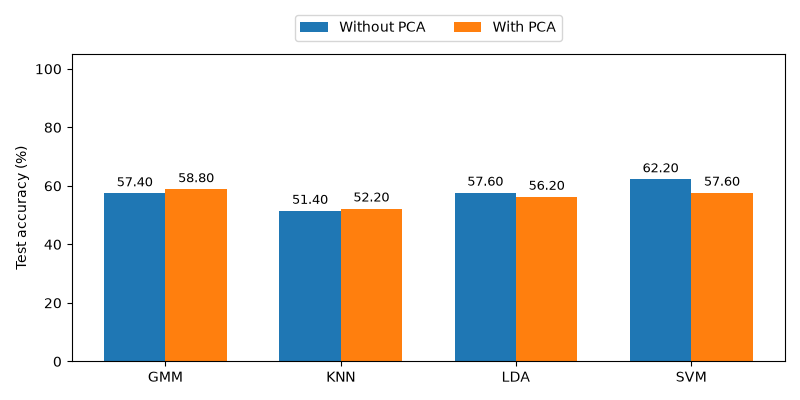

In [24]:
original_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                     [gmm_confusion, knn_confusion, lda_confusion, svm_confusion]]
pca_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                [gmm_pca_confusion, knn_pca_confusion, lda_pca_confusion, svm_pca_confusion]]
positions = np.arange(4)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
original_bars = ax.bar(positions - width / 2, original_accuracy, width, label="Without PCA")
pca_bars = ax.bar(positions + width / 2, pca_accuracy, width, label="With PCA")
ax.bar_label(original_bars, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(pca_bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(positions, ["GMM", "KNN", "LDA", "SVM"])
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=2)
plt.tight_layout()
plt.show()
